# Titanic — annotated walkthrough
Your original code and outputs are unchanged. Each markdown cell above a code cell explains **what** it does and **why**.

- **Part A — Cleaning (Lecture 5):** load → find hidden missing values → fix types → drop / fill columns → `df2`
- **Part B — Visualization and modeling prep (Lecture 6):** charts → correlation → X / y → train/test split → feature types

---
## Part A — Cleaning (Lecture 5)

### Imports
- `pandas` (as `pd`) — tables (DataFrames) and columns (Series)
- `numpy` (as `np`) — numeric tools; here it's used only for `np.nan`, the standard "missing value" marker

In [1]:
import pandas as pd
import numpy as np

### Load the data
`pd.read_csv` reads the CSV into a DataFrame called `df`: one row per passenger, one column per attribute.

In [2]:
df = pd.read_csv('Titanic.csv')

### First look — `head()`
Shows the first 5 rows. Notice the `?` in `boat` and `body`: this dataset marks missing values with `?`, **not** with an empty cell.

In [3]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,24160,211.3375,B5,S,2,?,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.55,C22 C26,S,11,?,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,113781,151.55,C22 C26,S,?,135,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"


### `info()` — columns, non-null counts, data types
Two things look wrong here:
1. **Every column says 1309 non-null.** That's because `?` is a real string, so pandas doesn't see it as missing.
2. **`age` and `fare` are `str`, not numbers.** One `?` in a column forces the whole column to be text.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   pclass     1309 non-null   int64
 1   survived   1309 non-null   int64
 2   name       1309 non-null   str  
 3   sex        1309 non-null   str  
 4   age        1309 non-null   str  
 5   sibsp      1309 non-null   int64
 6   parch      1309 non-null   int64
 7   ticket     1309 non-null   str  
 8   fare       1309 non-null   str  
 9   cabin      1309 non-null   str  
 10  embarked   1309 non-null   str  
 11  boat       1309 non-null   str  
 12  body       1309 non-null   str  
 13  home.dest  1309 non-null   str  
dtypes: int64(4), str(10)
memory usage: 143.3 KB


### Replace `?` with NaN
`df.replace('?', np.nan)` turns every `?` into a real missing value. After this, pandas can count missing values correctly.

In [5]:
df = df.replace('?', np.nan)

### `info()` again — the missing values are now visible
Compare with before: `age` 1046, `cabin` 295, `body` 121 and so on. Those gaps were there all along, hidden behind `?`.
`age` and `fare` are **still `str`**, because replacing `?` doesn't change a column's type.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   pclass     1309 non-null   int64
 1   survived   1309 non-null   int64
 2   name       1309 non-null   str  
 3   sex        1309 non-null   str  
 4   age        1046 non-null   str  
 5   sibsp      1309 non-null   int64
 6   parch      1309 non-null   int64
 7   ticket     1309 non-null   str  
 8   fare       1308 non-null   str  
 9   cabin      295 non-null    str  
 10  embarked   1307 non-null   str  
 11  boat       486 non-null    str  
 12  body       121 non-null    str  
 13  home.dest  745 non-null    str  
dtypes: int64(4), str(10)
memory usage: 143.3 KB


### Convert `age` to a number
`pd.to_numeric(..., errors='coerce')` converts text to numbers. `errors='coerce'` means "if a value can't be converted, make it NaN instead of crashing".

In [7]:
df['age'] = pd.to_numeric(df['age'], errors = 'coerce')

### Check — `age` is now `float64` ✓

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   str    
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    str    
 13  home.dest  745 non-null    str    
dtypes: float64(1), int64(4), str(9)
memory usage: 143.3 KB


### Convert several columns in one loop
The same `to_numeric` idea, applied to every column that should be numeric. `fare` and `body` become `float64`. The others were already numbers, so nothing changes for them.

In [9]:
column_list = ['age', 'sibsp', 'parch', 'fare', 'survived', 'pclass', 'body']

for col in column_list:
    df[col] = pd.to_numeric(df[col], errors='coerce')

### Check — `fare` and `body` are now `float64` ✓

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB


### How much is missing in each column?
- `df.isna().sum()` → the count of missing values per column
- dividing by `len(df)` and multiplying by 100 → the percentage
- `sort_values(ascending=False)` → worst column first

The percentages guide what to do with each column:
| Missing | Typical action |
|---|---|
| very high (`body` 91%, `cabin` 77%) | drop the column |
| moderate (`age` 20%) | fill (impute) it |
| tiny (`embarked`, `fare`) | fill it |

In [11]:
null_values = df.isna().sum().sort_values(ascending=False)
null_pct = (null_values/len(df)*100)
null_df = pd.DataFrame({'Null values':null_values, 'Null Percentage':null_pct})
print(null_df)

           Null values  Null Percentage
body              1188        90.756303
cabin             1014        77.463713
boat               823        62.872422
home.dest          564        43.086325
age                263        20.091673
embarked             2         0.152788
fare                 1         0.076394
sibsp                0         0.000000
name                 0         0.000000
survived             0         0.000000
pclass               0         0.000000
sex                  0         0.000000
parch                0         0.000000
ticket               0         0.000000


### Drop `body` and `cabin`
They are mostly empty, so there's too little information to fill them reliably.
`axis=1` means "drop **columns**" (`axis=0` would drop rows). The result goes into a new DataFrame, `df1`, so `df` is kept as it was.

In [12]:
df1 = df.drop(['body','cabin'], axis = 1)

### Check the result — `body` and `cabin` are gone

In [13]:
df1.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked,boat,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S,2,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S,11,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S,NaN,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S,NaN,"Montreal, PQ / Chesterville, ON"


### `info()` on `df1` — 12 columns left

In [14]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   embarked   1307 non-null   str    
 10  boat       486 non-null    str    
 11  home.dest  745 non-null    str    
dtypes: float64(2), int64(4), str(6)
memory usage: 122.8 KB


### Why `boat` must be dropped: target leakage
- people **with** a boat number: **98%** survived
- people **without** one: **3%** survived

`boat` almost *is* the answer. A lifeboat number is only known **after** you've survived, so a model trained on it would look great on paper and be useless for predicting new passengers. This is called **target leakage**.

In [15]:
print('Survived people with boat number %', round(df.loc[df.boat.notna(),'survived'].mean(),4)*100)
print('Survived people without boat number %', round(df.loc[df.boat.isna(),'survived'].mean(),4)*100)

Survived people with boat number % 98.15
Survived people without boat number % 2.79


### Same check for `body`
`body` is the number given to a recovered body, so everyone with a body number died (0% survival). It also leaks the answer.

In [16]:
print('Not Survived people with boat number %', round(df.loc[df.body.notna(),'survived'].mean(),4)*100)

Not Survived people with boat number % 0.0


### What's inside `boat`?
`unique()` lists the distinct values. They are mixed labels (`'2'`, `'D'`, `'13 15 B'`), so `boat` isn't a clean feature even apart from the leakage problem.

In [17]:
df['boat'].unique()

<StringArray>
[      '2',      '11',       nan,       '3',      '10',       'D',       '4',
       '9',       '6',       'B',       '8',       'A',       '5',       '7',
       'C',      '14',     '5 9',      '13',       '1',      '15',     '5 7',
    '8 10',      '12',      '16', '13 15 B',     'C D',   '15 16',   '13 15']
Length: 28, dtype: str

In [18]:
# Assignment = boat_assigned = 1 (who is survived), boat_assigned = 0 (who has not survived)

### Drop `boat` (leakage) and `home.dest` (43% missing, free text) → `df2`
**`df2` is the cleaned dataset that all of Lecture 6 uses.**

In [19]:
df2 = df1.drop(['boat', 'home.dest'], axis = 1)

### Look at `df2` — 1309 rows × 10 columns

In [20]:
df2

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S
...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,C
1305,3,0,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,C
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,C
1307,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,C


### What's still missing in `df2`
- `age` 263 missing
- `fare` 1 missing
- `embarked` 2 missing

In [21]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   str    
 3   sex       1309 non-null   str    
 4   age       1046 non-null   float64
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   ticket    1309 non-null   str    
 8   fare      1308 non-null   float64
 9   embarked  1307 non-null   str    
dtypes: float64(2), int64(4), str(4)
memory usage: 102.4 KB


### Fill missing `age` with the mode (most common value)
- `.mode()` returns a **Series**, because a column can have more than one mode
- `.iloc[0]` takes the first one as a single number (24.0)
- `.fillna(...)` puts it into every NaN

In [22]:
modes = df['age'].mode().iloc[0]
df2['age']= df2['age'].fillna(modes)

### Check — `age` now 1309 non-null ✓

In [23]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   str    
 3   sex       1309 non-null   str    
 4   age       1309 non-null   float64
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   ticket    1309 non-null   str    
 8   fare      1308 non-null   float64
 9   embarked  1307 non-null   str    
dtypes: float64(2), int64(4), str(4)
memory usage: 102.4 KB


### Why `.iloc[0]` is needed
This proves `.mode()` returns a Series and not a single value.

In [24]:
print(type(df2['age'].mode()))

<class 'pandas.Series'>


### The value used for filling: 24.0

In [25]:
print(modes)

24.0


### Fill missing `embarked`
`.fillna(modes)` puts the value stored in `modes` into the 2 missing `embarked` cells.

In [26]:
modes = df['age'].mode().iloc[0]
df2['embarked'] = df2['embarked'].fillna(modes)

### Fill missing `fare`
`.fillna(modes)` puts the value stored in `modes` into the 1 missing `fare` cell.

In [27]:
modes = df['age'].mode().iloc[0]
df2['fare'] = df2['fare'].fillna(modes)

### Mean vs median vs mode — which to use for filling?
| Use | When |
|---|---|
| **mean** | numeric, roughly symmetric, no big outliers |
| **median** | numeric with outliers or skew (`fare`, often `age`) |
| **mode** | categorical (`embarked`, `sex`) |

In [28]:
# median
# mode
#mean


---
## Part B — Visualization and modeling prep (Lecture 6)

### Plotting libraries
- `matplotlib.pyplot` (as `plt`) — the base plotting library: bars, labels, titles
- `seaborn` (as `sns`) — built on matplotlib; makes statistical plots straight from a DataFrame

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

### Notes 1 — First bar chart of passenger class
`plt.bar(x, heights)` draws one bar per x value.
- x = `unique()` → the classes, in the order first seen in the data: **1, 2, 3**
- heights = `value_counts()` → counts per class, **largest first**: 709, 323, 277

Compare this chart with the one two cells down to see why the order of x and heights matters.

In [56]:
df2['pclass'].value_counts()
df2['pclass']
df2['pclass'].unique()
df2['pclass'].value_counts().sort_index()

pclass
1    323
2    277
3    709
Name: count, dtype: int64

<BarContainer object of 3 artists>

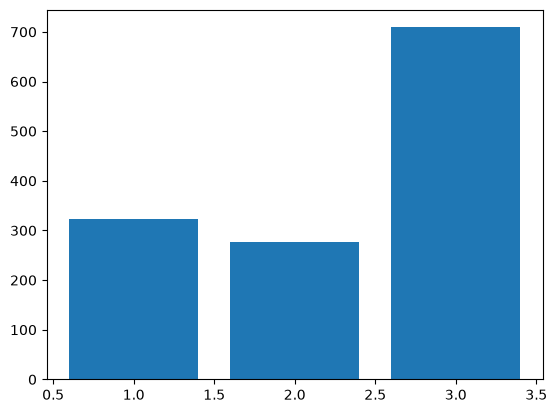

In [58]:
plt.bar(df2['pclass'].unique(), df2['pclass'].value_counts().sort_index())


### The real counts
Class 3 = 709, class 1 = 323, class 2 = 277. They add up to 1309.
The `pclass` index on the left shows `value_counts()` is sorted **by count, not by class**.

In [31]:
df2['pclass'].value_counts()

pclass
3    709
1    323
2    277
Name: count, dtype: int64

### Notes 1 — Corrected bar chart with labels
- `.sort_index()` reorders the counts to class 1, 2, 3, so they now match `unique()`
- `plt.bar` returns the bars (`a`); `plt.bar_label(a)` writes each bar's count on top
- `xlabel`, `ylabel`, and `title` label the chart

**Safer pattern:** take x and y from one Series, so they can never get out of step:
```python
counts = df2['pclass'].value_counts().sort_index()
plt.bar(counts.index, counts.values)
```

Text(0.5, 1.0, 'Class distribution of passenger in titanic')

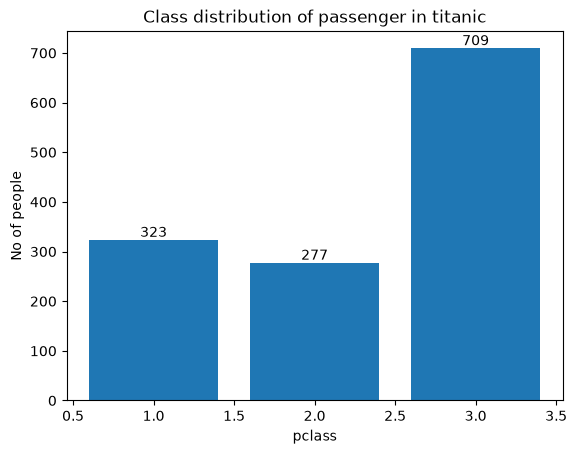

In [32]:
a = plt.bar(df2['pclass'].unique(), df2['pclass'].value_counts().sort_index())
plt.bar_label(a)
plt.xlabel('pclass')
plt.ylabel('No of people')
plt.title('Class distribution of passenger in titanic')

### Notes 1.1 — Count plot split by sex
- `sns.countplot` counts the rows itself, so there's no need for `value_counts()`
- `x='pclass'` → one group of bars per class
- `hue='sex'` → each class is split into male and female bars
- `ax.containers` → one container per hue group (male bars, female bars)
- the loop labels each container, because `bar_label` handles one container at a time
- `plt.show()` displays the plot

Chart is telling how many men and women were in each class

In [ ]:
ax = sns.countplot(data=df2,x='pclass',hue='sex')
for x in ax.containers:
    ax.bar_label(x)

ax.

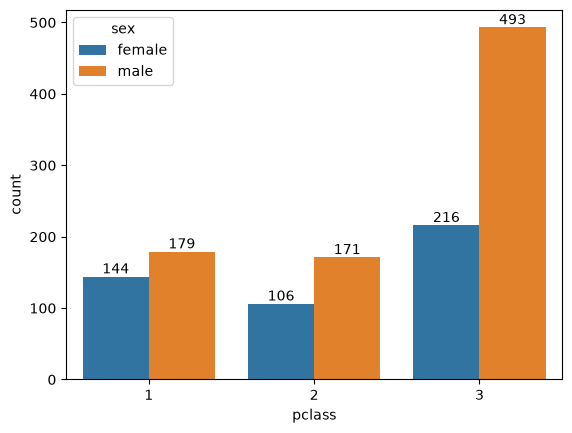

In [60]:
# How many male and female in class
ax = sns.countplot(data=df2,x='pclass',hue='sex')
for x in ax.containers:
    ax.bar_label(x)

# plt.show()

### Notes 2 — Survival counts split by sex
The same pattern with `x='survived'` (0 = died, 1 = survived).
It shows the lecture's key pattern: most survivors were female, and most deaths were male.

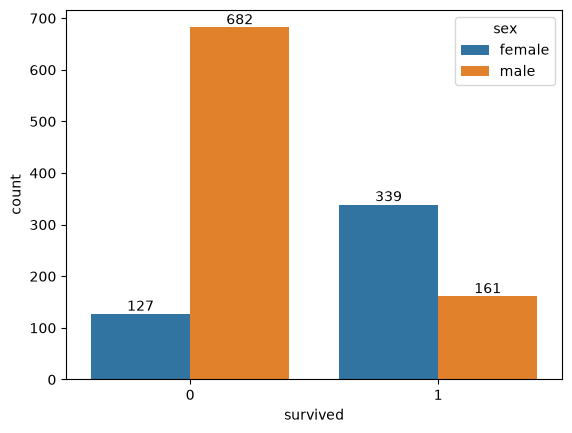

In [34]:
# How many of the survived are male and female
ay = sns.countplot(data=df2,x='survived',hue='sex')
for x in ay.containers:
    ay.bar_label(x)

plt.show()

### `info()` — final check before plotting relationships
All 10 columns are now 1309 non-null.

In [35]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   survived  1309 non-null   int64  
 2   name      1309 non-null   str    
 3   sex       1309 non-null   str    
 4   age       1309 non-null   float64
 5   sibsp     1309 non-null   int64  
 6   parch     1309 non-null   int64  
 7   ticket    1309 non-null   str    
 8   fare      1309 non-null   float64
 9   embarked  1309 non-null   object 
dtypes: float64(2), int64(4), object(1), str(3)
memory usage: 102.4+ KB


### Notes 3 — Correlation heatmap
- `.corr()` gives the Pearson correlation between every pair of numeric columns: −1 (opposite) … 0 (no linear link) … +1 (move together)
- `sns.heatmap` colors that table so strong links stand out

Things to look for:
- `pclass` vs `fare` is strongly **negative**: higher class number (3rd) means a cheaper ticket
- `pclass` vs `survived` is **negative**: 3rd class survived less

**Note (notes 3):** `pclass` is a category stored as 1, 2, 3, so its correlation depends on that numeric order.
**Tip:** `sns.heatmap(az, annot=True, fmt='.2f')` prints the numbers inside the cells.

<Axes: >

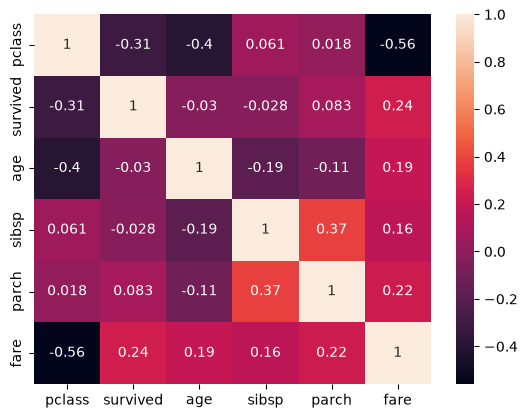

In [63]:
az = df2[['pclass','survived','age','sibsp','parch','fare']].corr()
#sns.heatmap(az)
sns.heatmap(az,annot=True)

### Distinct values of `pclass`, `sibsp`, `parch`
These show how many categories each column has before plotting:
- `sibsp` = number of siblings or spouses aboard
- `parch` = number of parents or children aboard

In [37]:
df2['pclass'].unique()

array([1, 2, 3])

In [38]:
df2['sibsp'].unique()

array([0, 1, 2, 3, 4, 5, 8])

In [39]:
df2['parch'].unique()

array([0, 2, 1, 4, 3, 5, 6, 9])

### Notes 4 and 5 — Histogram with KDE, split by survival
- `histplot` groups values into **bins** (ranges) and counts each one; `bins=8` gives 8 ranges
- `kde=True` adds a smooth curve estimating the shape of the distribution
- `hue='survived'` draws separate colors for died and survived

Note: `sibsp` only takes a few whole numbers (0–8), so a count plot (next cell) is easier to read here. Histograms suit truly continuous columns like `age` and `fare`.

<Axes: xlabel='sibsp', ylabel='Count'>

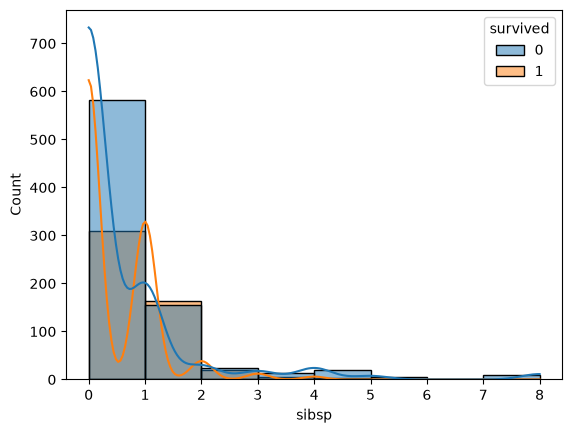

In [40]:
# how many poeple survived in sibsp
# am = df2[['sibsp','parch']]
sns.histplot(data=df2, x='sibsp',bins=8, kde=True, hue='survived')

### Notes 5 — Count plot of `sibsp` by survival
Same `countplot` + `bar_label` pattern as notes 1.1.
Pattern: passengers with 1–2 siblings or spouses survived proportionally more than those alone or in large families.

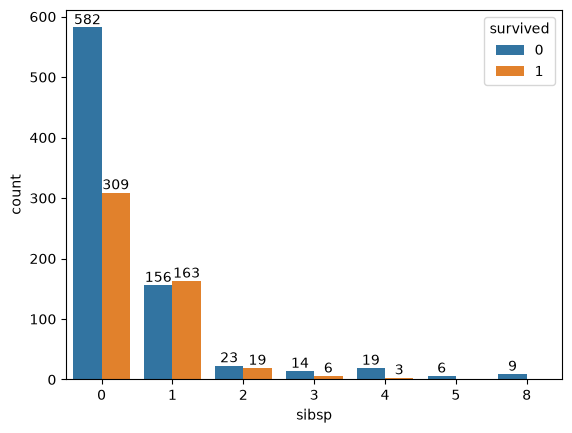

In [41]:
sns_values = sns.countplot(data= df2, x= 'sibsp', hue= 'survived')
for val in sns_values.containers:
  sns_values.bar_label(val)

### Notes 6 — Import the split function

In [42]:
from sklearn.model_selection import train_test_split

### Notes 6 — Separate the target `y` from the features `x`
- `y` = what we want to predict (`survived`)
- `x` = everything the model may use to predict it
- `drop(columns=['survived'])` removes the answer from the inputs

In [43]:
y = df2['survived']
x = df2.drop(columns=['survived'])

### Check `y` — a single column of 0s and 1s

In [44]:
y.head()

0    1
1    1
2    0
3    0
4    0
Name: survived, dtype: int64

### Check `x`
It still contains `name` and `ticket` (text) and `sex` and `embarked` (categories). These are the reason the model fit fails later (notes 8).

In [45]:
x.head()

,pclass,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S


### Notes 7 — Train/test split
- `test_size=0.2` → 20% held back for testing (262 rows), 80% for training (1047 rows)
- `random_state=5` → the same "random" split every time you run it, so results are repeatable
- `stratify=y` → train and test keep the **same survival ratio** as the full data

Why split at all? A model must be judged on passengers it **never saw** during training.

In [46]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2, random_state=5,stratify=y)

### Notes 8 — Import the model

In [47]:
from sklearn.linear_model import LogisticRegression

### Notes 9 — Feature types
- **Numerical** (`age`, `fare`, `sibsp`, `parch`): "how much / how many". These get **scaled**.
- **Categorical** (`pclass`, `sex`, `embarked`): "which group". These get **encoded** (turned into numbers).

**Also in `x` (notes 9):**
- `ticket` is identifier-like (almost unique per passenger), so it isn't a useful category and is usually dropped
- `name` is in neither list, but it's still in `x`, so it must be dropped (or engineered) before fitting

In [48]:
num_features = ['age','fare','sibsp','parch'] # (0-1) numerical feature = how, how many 
cat_features = ['pclass','sex','ticket','embarked'] # categorical feature = which , which class what type - (understand only on numbers) other way of scaling called encoding [encoding means change the categories to number] 

### Distinct values of `embarked`
Checks the categories in `embarked` before deciding how to encode it (notes 11).

In [49]:
df2['embarked'].unique()

array(['S', 'C', 24.0, 'Q'], dtype=object)

### Notes 10–12 — What comes next
- **Scaling** (notes 10) — puts numeric features on a similar scale. `StandardScaler` computes (value − mean) ÷ standard deviation.
- **Encoding** (notes 11) — turns categories into numbers. One-hot encoding makes one 0/1 column per category.
- **Feature selection** (notes 12) — choose which features to keep
- **Model optimization** (notes 12) — tune the model to get the best result

In [50]:
# what would scaling do to data (0-1) (-1,1)
# encoding (Simple encoding, one hot encoding)
# Fetaure selection, which, how many
# How to get the best model (Model optimization)


### Notes 8 — Why this fit is commented out
If you uncomment and run it, `model.fit` fails with a `ValueError` saying a string can't be converted to float. `LogisticRegression` only accepts numbers, and `x_train` still has text (`name`, `sex`, `ticket`, `embarked`).
That error is the reason for notes 9–11: identify feature types → scale the numeric ones → encode the categorical ones → then fit.

In [51]:
# model = LogisticRegression()
# model.fit(x_train,y_train)